# Фильтрация и управление

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sclin
import scipy.interpolate as scint
import scipy.special as spspec
#all imports here pls

Чтобы решить задачу управления, нужно обладать возможностью использовать состояния системы. Именно так строятся классические алгоритмы управления на основе принципа динамического программирования и приницпа максимума. Существенная характеристика данного подхода -- это марковость процесса состояний.

Если состояния системы наблюдаются не напрямую, а посредством технических приборов, задача резко усложняется в силу того, что управление может зависеть явно только от наблюдений, а не от состояний. При этом процесс наблюдения не является марковским, что естественно усложняет подход к конструкции управления. Алгоритмы фильтрации в этом смысле предлагают способ оценить ненаблюдаемое состояние и использовать его в качестве прокси для настоящего состояния. В некоторых задачах выполняется *принцип разделения* (или принцип декомпозиции), который утверждает, что управление, построенное таким образом будет оптимально. В общем случае доступны контрпримеры, но даже будучи субоптимальным управление на основе фильтра как правило является очень хорошим.

Ниже вам предлагаются две задачи, позволяющие исследовать эффект от того, что настоящие состояния больше недоступны для наблюдений.

В каждом примере ниже предполагается, что дано вероятностное пространство $(\Omega, \mathcal{F}, P)$ с определённой на нём фильтрацией $(\mathcal{F}_t)$ с подходящим индексным пространством для времени (дискретного или непрерывного), на которую мы будем ссылаться как на базовую.

## LQR в дискретном времени с наблюдениями (50 баллов)


Мы решали задачу LQR в непрерывном времени, давайте решим её в дискретном, на практике такие постановки тоже часто встречаются. Дискретность не всегда возникает из нежелания решать непрерывные задачи, некоторые задачи существуют только в дискретном виде. При правильно записанном пределе дискретизированная непрерывная версия является решением для дискретной задачи, но формулы оказываются проще в непрерывном случае -- по этой причине как правило его и рассматривают в более общих постановках.

Нам нужен дискретный случай, чтобы позже использовать готовую дискретную реализацию фильтра Калмана.

В дискретном времени задача становится небольшим упражнением на принцип динамического программирования и линейную алгебру.

### Постановка задачи

Система развивается согласно процессу `VAR(1)` со сносом и сигналом управления:

$$
X_{t+1} = \mu + AX_t + Bu_t + \xi_{t+1}, ~X_0 \sim N(x_0,\Lambda).
$$

где $\xi$ -- процесс гауссовского белого шума с распределением $N(0,R_x)$, согласованный с базовой фильтрацией, а параметры $\mu \in \mathbb{R}^d$ и $A \in \mathbb{R}^{d \times d}, B \in \mathbb{R}^{d \times k}, R_x \in \mathbb{R}^{d \times d}$.

Наблюдения происходят линейно по следующему закону:

$$
Y_{t} = CX_t + \eta_{t},
$$

где $\xi$ -- процесс гауссовского белого шума с распределением $N(0,R_y)$, согласованный с базовой фильтрацией, и матрица $C \in \mathbb{R}^{m \times d}$ задаёт систематическую ошибку.

Требуется найти управление $u$ в классе управлений, согласованное с фильтрацией $(\mathcal{F}_t^Y)$, дающее

$$
\min_u ~\mathbb{E} \left[ \sum_{t=0}^{T-1} \left\lbrace (X_t-x_*)^T Q (X_T-x_*) + u_t^T R u_t \right\rbrace + (X_T-x_*)^T Q_f (X_T-x_*) \right],
$$

где $Q,Q_f \in \mathbb{R}^{d \times d}, R \in \mathbb{R}^{k \times k}, x_* \in \mathbb{R}^d$, при этом полагается, что матрицы $Q,Q_f$ положительно полуопределённые, а $R$ строго положительно определённая.

Параметры динамики $\mu,A,B,R_x,x_0,\Lambda$, параметры наблюдения $C,R_y$, а также параметры критерия $x_*,Q,Q_f,R$ считаются данными и время $T$ задаётся фиксированным.

В качестве примера рассматривается [задача 2 с роботом отсюда](https://github.com/XuMuK1/psmo/blob/2025/homeworks/HW2.ipynb) с параметрами и графиками, как в оригинальом варианте.

### Вывод формул (10 баллов)

Запишите вывод формул для управления и функции Беллмана через принцип динамического программмирования. Она имеет вид
$$
V(t,x) = (x-x_*)^TF_t (x-x_*) + G_t (x-x_*) + H_t
$$
для подходяще подобранных матриц $F_t$.

Возможно, вам будет полезно [это](https://en.wikipedia.org/wiki/Matrix_calculus).

ЗДЕСЬ МОГЛО БЫТЬ ВАШЕ РЕШЕНИЕ

#### Управляемая модель с наблюдением

In [ ]:
## taken from https://github.com/XuMuK1/psmo/blob/2025/homeworks/HW2.ipynb
class LinearGaussianControlledSignalGenerator:

    def __init__(self, A, B, C, Rx, Ry, mu=0):
        """
        The model is 
        X_{t+1} = AX_t + B u_t +  V_t (unobservable)
        Y_{t+1} = CX_{t+1} + W_t (observable)
        """
        self.A=A
        self.B=B
        self.C=C
        self.Rx=Rx
        self.Ry=Ry
        self.mu = mu

        #add shape checks here


    def generate(self, N, start, feedbackControl, useTrueX=False, returnFiltered=False):
        """Generates simulation of process with observations

        Args:
            N (int): signal length
            start (float[]): start state (Y_0)
            feedbackControl (callable): map from state to control
            useTrueX (bool, optional): Whether to use true X for control (needed for diagnostics). Defaults to False.
            returnFiltered (bool, optional): Whether to return estimated states . Defaults to False.

        Returns:
            Xs,Ys,controls: states, measurements and controls up to pre-last time (d,T) (d,T) (k,T-1)
        """

        Xs = np.zeros([self.A.shape[0],N]) #signal
        Ys = np.zeros([self.C.shape[0],N]) #measurements
        controls = np.zeros([self.B.shape[1],N-1]) #controls
        Xs[:,0] = start
        Ys[:,0] = self.measurement(Xs[:,0])
        if(returnFiltered):
            filteredStates = np.zeros_like(Xs)[...,:-1] #same time as controls


        for i in np.arange(1,N):
            if(useTrueX):
                contrOut = feedbackControl(i-1,Ys[:,i-1],Xs[:,i-1],returnFiltered=returnFiltered)                
            else:
                contrOut = feedbackControl(i-1,Ys[:,i-1],returnFiltered=returnFiltered)

            if(returnFiltered):
                controls[:,i-1] = contrOut[0]
                filteredStates[:,i-1] = contrOut[1]
            else:
                controls[:,i-1] = contrOut
                
            Xs[:,i] = self.evolution(Xs[:,i-1], controls[:,i-1] )
            Ys[:,i] = self.measurement(Xs[:,i])

        if(returnFiltered):
            return Xs, Ys, controls, filteredStates
        else:
            return Xs, Ys, controls
    

    def measurement(self, x):
        """Measures the state x

        Args:
            x (float[]): state (d,)

        Returns:
            measurement float[]
        """        
        return self.C @ x + np.random.multivariate_normal(np.zeros([self.C.shape[0]]), self.Ry)
    
    def evolution(self, x, control):
        """Updates the state

        Args:
            x (float[]): current state (d,)
            control (float[]): control (k,)

        Returns:
            state float[]: new state
        """        
        return self.mu+self.A @ x + self.B @ control + np.random.multivariate_normal(np.zeros([self.A.shape[0]]), self.Rx)

Убедитесь, что у вас работает, запустив простой тест с произвольным управлением `feedbackController`.

In [ ]:


delta = 0.1 #time step
r=0.01 #friction
A = np.array([[1,0,delta,0],[0,1,0,delta],[0,0,1-r,0],[0,0,0,1-r]])
C = np.eye(4)

cx=0.98
cy =0.99
B = np.array([[0,0],[0,0],[cx*delta,0],[0, cy*delta]])

sigv2 = 0.1
Rx = np.array([[1e-15,0,0,0],[0,1e-15,0,0],[0,0,sigv2,0],[0,0,0,sigv2]])
Ry = np.eye(4)*50

generator = LinearGaussianControlledSignalGenerator(A,B,C,Rx,Ry)

startMean = np.array([5,5,0,0])
startCov = np.eye(4)*1e-5

x0 = np.zeros([4])
rad=10
def boundedControl(t,x,*args,**kwargs):
    normm =np.linalg.norm(x[:2]-x0[:2])
    if (normm >rad):
        return - (20 + np.random.standard_normal()*3 )* (x[:2]-x0[:2]) / normm
    else:
        return 0



In [ ]:
# Сгенерирруйте 500 наблюдений
start = np.random.multivariate_normal(mean=startMean,cov=startCov)
xs, ys, controls = generator.generate(500,start,boundedControl)

_, axs = plt.subplots(1,4,figsize=(18,3))

titles=["X","Y","Vx","Vy"]
for i in range(4):
    axs[i].grid()
    axs[i].set_title(f"Координата {titles[i]}",fontsize=16)
    axs[i].set_xlabel(f"t, время",fontsize=16)
    axs[i].plot(xs[i,:])
    axs[i].plot(ys[i,:],alpha=0.5)
    
axs[-1].legend(["Реал","Измерение"])

_,ax = plt.subplots(figsize=(5,3))

ax.grid()
ax.set_title("Управления")
ax.plot(controls[0,:])
ax.plot(controls[1,:])
ax.legend(["U1","U2"])



### Онлайн-фильтрация (5 баллов)

В построенном в первой части управлении остаётся один нюанс: оно зависит от состояния, а не от наблюдения. Во втором пункте в управление подаётся именно наблюдение. Чтобы завершить сборку алгоритма, понадобится подставить в управление оценку состояния, для этого в случае линейных систем оптимальным решением является фильтр Калмана.

Вам даётся готовая реализация фильтра и ваша задача состоит в том, чтобы перевести его в онлайн-формат (данная реализация полностью офлайн) и встроить в закон управления `LQR`.


In [ ]:
# https://github.com/XuMuK1/psmo/blob/2025/homeworks/HW2.ipynb
class KalmanFilterControlled:

    def __init__(self,A,B,C,Rx,Ry,startMean,startCov):
        """Kalman Filter for Linear Dynamic System of type

        X(t+1) = AX(t) + Bu(t) + U(t),      U(t)  iid  N(0,Rx)    (latent)
        Y(t+1) = CX(t+1) + W(t),    W(t)  iid  N(0,Ry)    (observable)
        X(0) ~ N(startMean, startCov)
        
        Basically, anything can be estimated but beware of divergence of EM-algorithm.
        Args:
            A (ndarray (d,d) ): dynamics matrix
            B (ndarray (d,m)): control matrix
            C (ndarray (k,d) ): observation matrix
            Rx (ndarray (d,d)): dynamics noise covariance
            Ry (ndarray (k,k)): observation noise covariance
            startMean (ndarray (d,)): dynamics start mean
            startCov (ndarray (d,d)): dynamics start covariance
        """        
        self.A = A
        self.B = B
        self.C = C 
        self.Rx = Rx
        self.Ry = Ry
        self.startMean = startMean
        if (startCov is None):
            self.startCov = np.eye(self.A.shape[0]) 
        else:
            self.startCov = startCov
            
    def __str__(self):
        return f"KalmanFilter,\n    A=\n    {self.A},\n    B=\n    {self.B},\n    Rx=\n    {self.Rx},\n    Ry=\n    {self.Ry},\n    startCov=\n    {self.startCov},\n    startMean=\n    {self.startMean}"

    def filterStep(self,apostX0,apostErr0,obs, control0=None):
        """Filtering step in Kalman algorithm

        Args:
            apostX0 (ndarray (d,) ): aposteriori prediction from the previous step
            apostErr0 (ndarray (d,d) ): its prediction error covariance
            obs (ndarray (k,) ): the current observation
            control0 (ndarray (m,) ): the control

        Returns:
            aprioriX ndarray (d,): current apriori prediction
            aprioriErr ndarray (d,d): current apriori prediction error covariance
            aposterioriX ndarray (d,): current aposteriori prediction
            aposterioriErr ndarray (d,d): current aposteriori prediction error covariance
            K ndarray (d,k): Kalman gain matrix
        """        
        
        aprioriX = self.A@apostX0 + self.B@control0
        aprioriErr = self.A@(apostErr0@(self.A.T)) + self.Rx #new apriori error
        K = aprioriErr@(self.C.T)@np.linalg.inv(self.Ry + self.C@aprioriErr@(self.C.T))# Kalman gain
        aposterioriX = aprioriX + K@(obs - self.C@aprioriX)
        aposterioriErr = aprioriErr - K@self.C@aprioriErr
        return aprioriX,aprioriErr,aposterioriX,aposterioriErr, K
    
    def filterSignal(self, signal, controls=None, returnK=False):
        """Performs filtration pass

        Args:
            signal (ndarray (d,T) ): observations to filter, X
            controls (ndarray (m,T-1) ): exogenous controls, U. Defaults to None
            returnK (bool, optional): whether to return Kalman gain matrix

        Returns:
            filteredSignal (ndarray (d,T)): filtered(or estimated) signal
            errs (ndarray (d,d,T)): filtered(or estimated) signal error covariance
            aprSignals (ndarray (d,T)): apriori predictions of the signal
            aprErrs (ndarray (d,d,T)): apriori predictions of the signal error covariance
            K (ndarray (d,K)): Kalman gain matrix (if returnK=True)
        """        
        
       
        filteredSignal = np.zeros([self.A.shape[0],signal.shape[-1]])
        aprSignals = np.zeros([self.A.shape[0],signal.shape[-1]])
        errs = np.zeros([self.A.shape[0],self.A.shape[0],signal.shape[-1]])
        aprErrs = np.zeros([self.A.shape[0],self.A.shape[0],signal.shape[-1]])

        #init, no control
        aprSig,aprErr,apostSig,apostErr, K = self.filterStep(self.startMean, self.startCov, signal[:, 0], controls[:, 0]*0)            
        aprSig0 = apostSig
        aprErr0 = apostErr        
        filteredSignal[:,0] = apostSig
        errs[:,:,0] = apostErr
        aprSignals[:,0] = aprSig
        aprErrs[:,:,0] = aprErr

        for i in np.arange(1,signal.shape[1]):
            aprSig,aprErr,apostSig,apostErr, K = self.filterStep(aprSig0, aprErr0, signal[:, i], controls[:, i - 1])
            
            aprSig0 = apostSig
            aprErr0 = apostErr
            filteredSignal[:,i] = apostSig
            errs[:,:,i] = apostErr
            aprSignals[:,i] = aprSig
            aprErrs[:,:,i] = aprErr

        if(returnK):
            return filteredSignal, errs, aprSignals, aprErrs, K
        else:
            return filteredSignal, errs, aprSignals, aprErrs
    
            


Для онлайн-версии удобно отнаследоваться от офлайн-версии.

In [ ]:
#YOUR KALMAN FILTER

# https://github.com/XuMuK1/psmo/blob/2025/homeworks/HW2.ipynb
class KalmanFilterControlledOnline(KalmanFilterControlled):

   ????????????????????????????????????????????

    def __call__(self,obs,control0):
        """
        Filters the observation

        Args:
            obs (float[]): observation (m,)
            control0 (float[]): control at previous time (time0) (k,)

        Returns:
            estState float[]: estimated state (d,)
        """        
        raise NotImplementedError

    def reset(self):
        self.currentXEst = self.startMean
        self.currentErrorEst = self.startCov


Попробуйте сначала протестировать свой фильтр и убедиться, что он действительно как-то работает. Можете использовать код ниже как основу.

In [ ]:
#setup same as before

delta = 0.1 #time step
r=0.01 #friction
A = np.array([[1,0,delta,0],[0,1,0,delta],[0,0,1-r,0],[0,0,0,1-r]])
C = np.eye(4)

cx=0.98
cy =0.99
B = np.array([[0,0],[0,0],[cx*delta,0],[0, cy*delta]])

sigv2 = 0.1
Rx = np.array([[1e-15,0,0,0],[0,1e-15,0,0],[0,0,sigv2,0],[0,0,0,sigv2]])
Ry = np.eye(4)*50

generator = LinearGaussianControlledSignalGenerator(A,B,C,Rx,Ry)

startMean = np.array([5,5,0,0])
startCov = np.eye(4)*1e-5

x0 = np.zeros([4])
rad=10
def boundedControl(t,x,*args,**kwargs):
    normm =np.linalg.norm(x[:2]-x0[:2])
    if (normm >rad):
        return - (20 + np.random.standard_normal()*3 )* (x[:2]-x0[:2]) / normm 
    else:
        return 0


In [ ]:
start = np.random.multivariate_normal(mean=startMean,cov=startCov)
xs, ys, controls = generator.generate(100,start,boundedControl)
print(xs.shape,ys.shape,controls.shape)

kf = KalmanFilterControlled(A,B,C,Rx,Ry, startMean, startCov)
kfOnline = KalmanFilterControlledOnline(A,B,C,Rx,Ry, startMean, startCov)
filteredSignal, errs, _,_,Ks1 = kf.filterSignal(ys, controls, returnK=True)
def inferenceOnlineKF(ys,controls):
    #init, no control
    ????
    return FILTERINGRESULT

filteredSignal2 = inferenceOnlineKF(ys,controls)
print(np.sum(np.abs(filteredSignal-filteredSignal2)))
        


_, axs = plt.subplots(1,4,figsize=(18,3))

titles=["X","Y","Vx","Vy"]
for i in range(4):
    axs[i].grid()
    axs[i].set_title(f"Координата {titles[i]}",fontsize=16)
    axs[i].set_xlabel(f"t, время",fontsize=16)
    axs[i].plot(xs[i,:])
    axs[i].plot(ys[i,:],alpha=0.5)
    axs[i].plot(filteredSignal2[i,:],alpha=0.5)
    
axs[-1].legend(["Реал","Измерение","Фильтр"])

_,ax = plt.subplots(figsize=(5,3))

ax.grid()
ax.set_title("Управления")
ax.plot(controls[0,:])
ax.plot(controls[1,:])
ax.legend(["U1","U2"])



#### Модифицированный LQR с наблюдением и связка с фильтром Калмана (10 баллов)

Теперь реализуем `LQRController`, в нашем случае он должен принимать сигнал наблюдения на вход, как-то его обрабатывать с помощью `self.stateEstimator` и использовать в аналитически полученном законе управления.

In [ ]:
    
class LQRController:
    
    def __init__(self, A,B,Q,R,mu, stateEstimator):
        """LQR instance with xstar=const tracking

        Args:
            A (float[]): dynamics matrix (d,d)
            B (float[]): control matrix (d,k)
            Q (float[]): reconstruction error matrix from LQR (d,d)
            R (float[]): control cost matrix from LQR (k,k)
            mu (float[]): fixed deviation (d,)
            stateEstimator (callable): a callable object recieving previous control and current observation and returning state estimate, (control,obs) -> stateEst
        """        
        self.A = A
        self.B = B
        self.Q = Q
        self.R = R
        self.Rinv= np.linalg.inv(self.R)
        self.mu = mu
        self.stateEstimator = stateEstimator
        self.initParams() #F,G,H=None
        
    def initParams(self):
        """
        Resets the parameters of LQR functions
        """        
        self.F = None #fun(t)
        self.G = None
        self.H = None
        self.fixedGain = None # numbers
        self.xstar = None
        self.stateEstimator.reset()
        #whatever you need here
        
    def __call__(self,t,y,x=None, returnFiltered=False):
        """Computes LQR control

        Args:
            t (float): time
            y (float[]): observation (m,)
            x (float[], optional): state, needed for diagnostics. Defaults to None.
            returnFiltered (bool, optional): whether to return filtering result. Defaults to False.

        Returns:
            u float[]: control (k,)
            or
            u float[], xEst float[]: control (k,) and state estimate
        """                 
        
        ??????????

        
    
    def fit(self,xstar, ts, P=None):
        """Fits the LQR Bellman function parameters

        Args:
            xstar (float[]): steady-state point
            ts (float[]): time grid T,)
            P (float[], optional): Terminal condition for Riccati differential equation. Defaults to None.
        """        
        if(P is None):
            P = np.zeros_like(self.Q)

        self.xstar = xstar
        ?????
        
         #   self.Fs[??,...] = ????      
         #   self.Gs[??,...] = ???

        
        self.F =??
        self.G =??        
        
            
    

В качестве теста попробуйте сначала вместо `stateEst` подставить настоящее состояние, это можно реализовать через служебный флаг при инициализации.

Наблюдение теперь урезано до координат, скорости напрямую не наблюдаются (какая в этом случае должна быть матрица наблюдений?). Для диагностики можете пробовать `C=eye(4)`, чтобоы проверить, что в идеальном случае управление всё ещё работает.

In [ ]:
delta = 0.1 #time step
r=0.01 #friction
A = np.array([[1,0,delta,0],[0,1,0,delta],[0,0,1-r,0],[0,0,0,1-r]])
C = ???
#C = np.eye(4)

cx=0.98
cy =0.99
B = np.array([[0,0],[0,0],[cx*delta,0],[0, cy*delta]])

sigv2 = 0.01
Rx = np.array([[1e-15,0,0,0],[0,1e-15,0,0],[0,0,sigv2,0],[0,0,0,sigv2]])
Ry = np.eye(2)*50

generator = LinearGaussianControlledSignalGenerator(A,B,C,Rx,Ry)

startMean = np.array([5,5,0,0])
startCov = np.eye(4)*1e-5

xstar = np.array([15,-10,0,0])#try zeros first for testing

In [ ]:
kfOnline = KalmanFilterControlledOnline(A,B,C,Rx,Ry,startMean,startCov)
Q = np.eye(4)*5
R = np.eye(2)*2
lqrController = LQRController(A,B,Q,R,np.zeros([4]),kfOnline)
lqrController.fit(xstar,???????????????)
xs,ys,controls,filteredStates = generator.generate(?????????????)
print(xs.shape,ys.shape,controls.shape,filteredStates.shape)


In [ ]:
_, axs = plt.subplots(1,4,figsize=(18,3))

titles=["X","Y","Vx","Vy"]
for i in range(4):
    axs[i].grid()
    axs[i].set_title(f"Координата {titles[i]}",fontsize=16)
    axs[i].set_xlabel(f"t, время",fontsize=16)
    axs[i].plot(xs[i,:],color="blue")
    try:
        axs[i].plot(ys[i,:],alpha=0.5,color="red")
    except IndexError as ie:
        print(f"Observation {i} is broken or not avaliable")
    axs[i].plot(filteredStates[i,:],alpha=0.5,color="green")
    
axs[0].legend(["Реал","Измерение","Фильтр"])
#axs[-1].legend(["Реал","Измерение","Фильтр"])
axs[-1].legend(["Реал","Фильтр"])

_,ax = plt.subplots(figsize=(5,3))

ax.grid()
ax.set_title("Управления")
ax.plot(controls[0,:],alpha=0.5)
ax.plot(controls[1,:],alpha=0.5)
ax.legend(["U1","U2"])


### Финальные сравнения (25 баллов)

Сопоставьте три закона управления:
1. Управление при полной наблюдаемости
2. Управление с фильтром Калмана
3. Наивное управление `boundedControl` из начала

Используя изначально заданный `xstar=[15,-10,0,0]`:
 - Постройте на основе приложенного примера `N=100` симуляций, усредните результаты получившихся траекторий состояния, постройте графики, отобразив в одних осях стостояние, результат фильтрации и наблюдение (если наблюдение есть).
 - Сравните среднюю ошибку `x-xstar` и её дисперсию для `Q=alpha*np.eye(4)` для пяти разных `alpha` и для `R=beta*np.eye(2)` при пяти разных `beta`. 
 - Сделайте вывод о том, как ошибка зависит от выбора этих гиперпараметров.

Какие есть преимущества и недостатки у наивного управления и управления с фильтром?


ЗДЕСЬ МОГЛИ БЫ БЫТЬ ВАШИ КОММЕНТАРИИ И ГРАФИКИ

## Переключающийся LQR в непрерывном времени (50 баллов)

В этом задании мы исследуем задачу LQR, где состояния полностью наблюдаются, но в самой динамике могут происходит случайные изменения. Общий класс таких моделей называется *моделями с переключениями*. Такие модели стали особенно популярные в последние 15-20 лет в макроэкономике (см. [тут](https://www.sciencedirect.com/science/article/abs/pii/S0022053109000787?fr=RR-2&ref=pdf_download&rr=a51b04b15ae79d8f), [тут](https://www.sciencedirect.com/science/article/abs/pii/S0165188921001706) и [тут](https://www.sciencedirect.com/science/article/abs/pii/S0165188911000649)) в контексте планирования фискальной и монетарной политики, а также являются одной из базовых идея для управления оборудованием в режимах разладки.

### Постановка задачи

Пусть $W$ -- винеровский процесс, согласованный с базовой фильтрацией, $X_0 = x_0 \in \mathbb{R}^d$, состояния изменяются по закону

$$
dX_t = (A_{Y_t}X_t + B_{Y_t}u_t)dt + \sigma_{Y_t} dW_t, ~ ~~ A_{Y_t} \in \mathbb{R}^{d\times d}, B_{Y_t} \in \mathbb{R}^{d \times k}, \sigma_{Y_t} \in \mathbb{R}^{d \times d},
$$

где параметры динамики зависят от режима $Y$, который моделируется как цепь Маркова со значениями в конечном множестве $\Xi=\lbrace 1,..,N \rbrace$ в непрерывном времени с инфинитезимальным генератором $L$ (Q-матрицей) и $Y_0=y_0 \in \Xi$.

Требуется построить управление $u$ в классе управлений, согласованных с фильтрацией $\mathcal{F}_t^X$ и дающих

$$
\min_u \mathbb{E}\left[ \int_0^\infty (X_t-x_*)^T Q (X_t-x_*) + u_t^T R u_t dt\right],
$$

где матрицы $Q,Q_f \in \mathbb{R}^{d \times d}$ симметричные и положительно полуопределённые, а матрица $R \in \mathbb{R}^{k \times k}$ симметрична и строго положительно определена.

Как и раньше, все параметра предполагаются данными.

Мы будем строить алгоритм управления в несколько этапов:
1. Решение управления для каждого отдельного режима.
2. Построения алгоритма фильтрации режима на основе наблюдений с помощью уравнения Кушнера-Стратоновича.
3. Совмещение двух алгоритмов в одном, где управление выбрается на основе оценённого режима, тут тоже есть свобода настройки.

### Оценка текущего режима (25 баллов из 50)

Для построения фильтра нужно использовать уравнение Закая и/или уравнение Кушнера-Стратоновича. Для простоты мы положим, что эти уравнения верны и в нашем случае (можете повторить вывод, там не меняется практически ничего). Единственный вопрос -- что такое инфинитезимальный оператор для цепи Маркова в непрерывном времени.

#### Инфинитезимальный генератор

По определению инифинитезимальным оператором (генератором) процесса называется оператор $L$, действующих на функциях $\phi: \Xi \to \mathbb{R}$ (где $\Xi$ -- пространство состояний случайного процесса) как

$$
L[\phi](x) = \lim_{t \to 0+} \frac{\mathbb{E}\left[ \phi(X_t)~\vert~X_0=x\right] - \phi(x)}{t}.
$$

Рассмотрим цепь Маркова в непрерывном времени $X$ с $N$ состояниями из нашего задания с Q-матрицей $D$ (буква $Q$ уже занята, к сожалению). Как будет определяться генератор?

ЗДЕСЬ МОГЛО БЫТЬ ВАШЕ РЕШЕНИЕ

$L[\phi](x)=....$

#### Уравнения фильтрации (случай, когда динамика наблюдения не зависит от наблюдения)

Начнём с фильтра, который работает с цепью Маркова в непрерывном времени $X$ в качестве состояний и уравнением

$$
dY_t = h(X_t)dt + \sigma dW_t
$$
в качестве наблюдений. Это попадает в рамки рассматриваемых нами ранее постановок. 

Выпишите уравнение Закая и уравнение Кушнера-Стратоновича для апостериорных мер процесса $X$, не забудьте про $\sigma$.

ВАШЕ УРАВНЕНИЕ 1

ВАШЕ УРАВНЕНИЕ 2

В этом задании вы можете использовать любое из них. Постройте алгоритм фильтрации, оценивающий апостериорные вероятности $\pi_t^k=P(X_t=k \vert \mathcal{F}_t^Y)$ и обоснуйте свой выбор.

Полученный фильтр носит название фильтра Вонхема-Ширяева ([Wonham 1965](https://epubs.siam.org/doi/10.1137/0302028), [Ширяев 1966](https://www.mathnet.ru/php/archive.phtml?wshow=paper&jrnid=ppi&paperid=1954&option_lang=rus) ), у А.Н. Ширяева рассматривается более общий случай. Полученные в статьях уравнения -- частные случаи уравнения Кушнера-Стратоновича. 

Наивная дискретизация по времени однако не сработает для решения этого уравнения, так как не гарантирована положительность вероятностей. 

Помимо этого есть и другие проблемы с численным решением, они чинятся, об этом ниже.

#### Уравнения фильтрации (случай, когда динамика наблюдения зависит от наблюдения)

В нашем случае формально задача не совсем такая, наблюдения устроены по-другому: в задаче переключающегося LQR сами наблюдения включены в уравнение наблюдений, то есть

$$
dY_t = (\mu_{X_t}+A_{X_t}Y_t + Bu_t)dt +  \sigma dW_t,
$$

Из-за этого меняется производная Радона-Никодима в замене меры на

$$
F_t = \text{exp}\left\lbrace-\int_0^t (h(X_s,Y_s))^T dW_s - \frac{1}{2}\int_0^t \Vert \sigma^{-1}h(X_s,Y_s) \Vert_2^2 ds \right\rbrace,
$$
где $h(X_s,Y_s)=\mu_{X_t}+A_{X_s}Y_s + Bu_s$. Удивительно, но уравнения фильтрации изменятся только в части этого дрейфа (вы можете проделать вывод для себя сами, формально это необходимо, но отдельно этого в задании не требуется).

Запишите ваше новое уравнение для апостериорных вероятностей (нормированных или ненормированных, в зависимости от выбранного подхода).

ЗДЕСЬ МОГЛО БЫТЬ ВАШЕ НОВОЕ УРАВНЕНИЕ

#### Имплементация и тестирование (15 из 25 баллов)

Реализуйте модель наблюдения в переключающемся LQR и используйте выведенные вами уравнения, чтобы сконструировать фильтр. Сделайте офлайн- и онлайн-версию фильтра (находится ближе к концу блока), чтобы было удобнее тестировать, рекомендуется реализовать сначала офлайн-фильтр, а потом отнаследовать от него онлайн-фильтр, дописав необходимый функционал. Офлайн фильтр тестировать проще.

Специально для вашего комфорта ниже написан класс для цепи Маркова в непрерывном времени, вам нужно его интегрировать в `RegimeSwitchingLinearSystem`.

Будьте внимательны при имплементации фильтра Вонхема-Ширяева, у него при решении есть несколько проблем, которые вам нужно починить:
1. Нормировать/ненормировать вероятности (уравнение Кушнера-Стратоновича или уравнение Закая)?
2. Как делать шаг обновления, чтобы избежать вычислительных коллапсов и обеспечить стабильность фильтра?
3. Какую схему численной аппроксимации использовать?
4. Как гарантировать положительность вероятности?

Постройте алгоритм фильтрации и обоснуйте свой выбор. Опишите кратко ниже, в чём состоит ваше итоговое решение.

МЕСТО ДЛЯ ВАШИХ ОБЪЯСНЕНИЙ

In [ ]:
class CTMC: #continuous-time Markov chain

    def __init__(self,Qmatrix):
        """Continuous-time Markov chain (CTMC)

        Args:
            Qmatrix (float[]): infinitesimal generator of CTMC
        """        
        self.Qmatrix = Qmatrix
        self.stateIds = np.arange(self.Qmatrix.shape[0])

    def simulate(self,T, startProbas):
        """Simulates one trajectory of CTMC

        Args:
            T (float): terminal time
            startProbas (_type_): _description_

        Returns:
            jumpTimes float[], states int[]: jump times and new states
        """        
        states = [np.random.choice(np.arange(self.Qmatrix.shape[0]),p=startProbas)]
        jumpTimes = []
        while(len(jumpTimes)==0 or jumpTimes[-1]<T):
            dt = np.random.exponential(-1/self.Qmatrix[states[-1],states[-1]])
            if(len(jumpTimes)==0):
                jumpTimes.append(dt)
            else:
                jumpTimes.append(jumpTimes[-1]+dt)
            probas = -self.Qmatrix[states[-1],:]/self.Qmatrix[states[-1],states[-1]]
            mask = self.stateIds!=states[-1]
            probas = probas[mask]
            states.append(np.random.choice(self.stateIds[mask],p=probas))

        return np.array(jumpTimes),np.array(states)


class RegimeSwitchingLinearSystem:

    def __init__(self,Qmatrix,mus,As,B,sigma):
        """Linear SDE with switching

        Args:
            Qmatrix (float[]): infinitesimal generator of CTMC
            mus (list float[]): fixed deviations (d,)
            As (list float[]): dynamics matrices (d,d)
            B (float[]): control matrix (d,k)
            sigma (float[]): noise square-root covariance
        """        
        self.Qmatrix = Qmatrix
        self.ctmc = CTMC(Qmatrix)
        self.As = As
        self.d = self.As[0].shape[0]
        self.mus = mus
        self.B = B
        self.sigma = sigma

    def simulateRegime(self,T,startProbas):
        """Simulates regime process set by CTMC

        Args:
            T (float): terminal time
            startProbas (float[]): initial distribution of CTMC

        Returns:
            jumpTimes float[], states int[]: jump times and new states
        """        
        jumpTimes, states = self.ctmc.simulate(T,startProbas)
        return jumpTimes, states

    def measurementStep(self,y,state,control,dt):
        """Diffusion update set by the regime

        Args:
            y (float[]): current value
            state (int): current state of regime CTMC
            control (float[]): control (k,)
            dt (float): delta time of the update

        Returns:
            newState float[]: new state
        """        
        return ????????????????????

    def drift(self,y,control):
        """Drift function, computed for all possible states at fixed diffusion value

        Args:
            y (float[]): diffusion value (d,)
            control (cfloat[]): control (k,)

        Returns:
            drifts float[]: (N,d) matrix of drifts, depicted in formulas as h^T
        """        
        return ??????????????????????????

    def simulate(self,ts,feedbackControl,startProbas,startY,returnFiltered=False,useTrueState=False):
        """Simulates trajectories of switching linear system

        Args:
            ts (float[]): times
            feedbackControl (obj): object implementing __call__ mapping t,y,state,returnFIltered -> control or control, apostProbas
            startProbas (float[]): initial distribution of CTMC
            startY (float[]): diffusion initial value
            returnFiltered (bool, optional): whether to return aposteriori probabilities. Defaults to False.
            useTrueState (bool, optional): whether to use true regime instead of filtered (needed for diagnostics). Defaults to False.

        Returns:
            Ys float[]. jumpTimes float[], states float[], controls float[]: diffusion values, jumps, jump states, controls
            Ys float[]. jumpTimes float[], states float[], controls float[], filteredProbas[]: with additional filtered probabilities
        """        
        ????
        #YOUR CODE HERE
    

In [ ]:
class WSFilter:

    def __init__(self, startProbas, Qmatrix, driftFunction, noiseSigma):
        """Wonham-Shiryaev Filter for switching LQR

        Args:
            startProbas (float[]): vector of start probabilities for Markov chain (MUST SUM UP TO ONE) (N,)
            Qmatrix (float[]): Qmatrix of Markov chain
            driftFunction (callable): drift values corresponding to each state, maps Y,u -> (h(Y,xi_1,u),...,h(Y,xi_N,u)) for all xi_i -- states of MC
            noiseSigma (float[]): Noise square-root covariance, assumed to be invertible (m,m)
        """        
        self.Qmatrix = Qmatrix
        self.driftFunction = driftFunction
        self.noiseSigma = noiseSigma
        self.noiseSigmaInv = np.linalg.inv(noiseSigma)#precompute
        self.startProbas = startProbas

    def filterStep(self,apostP0,obs0,obs,control,dt):
        """Filter step

        Args:
            apostP0 (float[]): previous aposteriori probabilities
            obs0 (float[]): previous observation 
            obs (float[]): current observation
            control (float[]): previous control
            dt (float): delta time

        Returns:
            aspotProbas float[]: filtered aposteriori probabilities
        """        
        ????????????????
        return apostProbas

    def filterSignal(self, ys, controls, ts):
        """
        Filters the whole signal with given sequence of controls 

        Args:
            ys (float[]): diffusion observations (T,)
            controls (float[]): controls (T-1,)
            ts (float[]): times (T,)

        Returns:
            apostProbas float[]: aposteriori probabilities (d,T)
        """        
       
        ?????????????????

        return apostProbas


Чтобы проверить, как работает фильтр Вонхема-Ширяева, для начала рассмотрите самый простой сценарий $A=0,B=0,u_t=0$ два режима $\mu_0=3,\mu_1=-1$. Это соответствует классической задаче Вонхема.

In [ ]:
Qmatrix = np.array([[-0.4,0.4],[0.1,-0.1]])
As = [np.zeros([1,1]),np.zeros([1,1])]
B = np.zeros([1,1])
mus = [np.array([1]),np.array([-1])]
sigma = np.eye(1)*2
startProbas = np.array([0.05,0.95])
T=100
ts = np.linspace(0,T,200)
startY = np.zeros([1])

switchingModel = RegimeSwitchingLinearSystem(Qmatrix,mus,As,B,sigma)
def zeroFeedback(t,y,*args,**kwargs):
    return np.zeros(B.shape[1])
ys,jumpTimes,states,controls = switchingModel.simulate(ts,zeroFeedback,startProbas,startY)

Теперь попробуйте использовать фильтр Вонхэма, чтобы вычислить апостериорные вероятности режимов.

In [ ]:
def driftFunction(obs,control):
    return switchingModel.drift(obs,control)
wsFilter = WSFilter(startProbas,Qmatrix,driftFunction,sigma)
apostProbas = wsFilter.filterSignal(ys,controls,ts)

In [ ]:
extendedJumpTimes = np.concatenate([np.array([0]),jumpTimes])

f, axs = plt.subplots(2,1,figsize=(9,9))

axs[0].grid()
axs[0].set_title("Динамика наблюдений",fontsize=16)
#axs[0].set_xlabel("Время",fontsize=16)
regimeColors = ['blue','red']
for t0, t1, state in zip(extendedJumpTimes[:-2], extendedJumpTimes[1:-1],states): #https://stackoverflow.com/questions/67091501/how-do-i-plot-vertical-strips-in-matplotlib
    axs[0].axvspan(t0, t1, color=regimeColors[state], alpha=0.1, lw=0)
axs[0].axvspan(extendedJumpTimes[-2], ts[-1], color=regimeColors[states[-2]], alpha=0.1, lw=0)

axs[0].plot(ts,ys[0,:])

axs[1].grid()
axs[1].set_title("Динамика состояний",fontsize=16)
axs[1].set_xlabel("Время",fontsize=16)
axs[1].plot(ts,scint.interp1d(extendedJumpTimes,states,kind="previous")(ts))
axs[1].plot(ts,apostProbas[1,:],alpha=0.5)
axs[1].legend(["Состояние","Pi1"])


plt.setp(axs, xlim=axs[0].get_xlim())


Фильтр не делает чудес, много определяет соотношение энергии сигнала и шума (SNR, Signal-to-Noise Ratio). Если шума много, то оценивать сложно, тем более что наблюдения сами раздувают шум. Если попробовать разные `sigma`, то можно увидеть, что детектор не так всемогущ, но он позволяет извлечь максимум апостериорной информации из сигнала (больше сделать теоретически невозможно в рамках заданных предположений).

Теперь попробуйте рассмотреть переключающийся процесс, добавив ненулевые матрицы динамики к сносу.

In [ ]:
Qmatrix = np.array([[-0.4,0.4],[0.1,-0.1]])
As = [np.array([0]),np.array([0.1])]
B = np.zeros([1,1])
mus = [np.array([0.1]),np.array([-0.1])]
sigma = np.eye(1)*2
startProbas = np.array([0.05,0.95])
T=100
ts = np.linspace(0,T,200)
startY = np.zeros([1])

switchingModel = RegimeSwitchingLinearSystem(Qmatrix,mus,As,B,sigma)
ys,jumpTimes,states,controls = switchingModel.simulate(ts,zeroFeedback,startProbas,startY)

def driftFunction(obs,control):
    return switchingModel.drift(obs,control)
wsFilter = WSFilter(startProbas,Qmatrix,driftFunction,sigma)
apostProbas = wsFilter.filterSignal(ys,controls,ts)

In [ ]:
extendedJumpTimes = np.concatenate([np.array([0]),jumpTimes])

f, axs = plt.subplots(2,1,figsize=(9,9))

axs[0].grid()
axs[0].set_title("Динамика наблюдений",fontsize=16)
#axs[0].set_xlabel("Время",fontsize=16)
regimeColors = ['blue','red']
for t0, t1, state in zip(extendedJumpTimes[:-2], extendedJumpTimes[1:-1],states): #https://stackoverflow.com/questions/67091501/how-do-i-plot-vertical-strips-in-matplotlib
    axs[0].axvspan(t0, t1, color=regimeColors[state], alpha=0.1, lw=0)
axs[0].axvspan(extendedJumpTimes[-2], ts[-1], color=regimeColors[states[-2]], alpha=0.1, lw=0)

axs[0].plot(ts,ys[0,:])

axs[1].grid()
axs[1].set_title("Динамика состояний",fontsize=16)
axs[1].set_xlabel("Время",fontsize=16)
axs[1].plot(ts,scint.interp1d(extendedJumpTimes,states,kind="previous")(ts))
axs[1].plot(ts,apostProbas[1,:],alpha=0.5)
axs[1].legend(["Состояние","Pi1"])


plt.setp(axs, xlim=axs[0].get_xlim())

Насколько ваш фильтр умело справляется с переключениями, что у него вызывает наибольшие сложности: параметры режимов, частота смены? На что влияет временная дискретизация?

Попробуйте ответить на этот вопрос, опираясь на экспериментальные данные.

In [ ]:
#MORE CHARTS!!!

ЗДЕСЬ МОГ БЫТЬ ВАШ КОММЕНТАРИЙ

Проверьте в окне ниже на одном из построенных примеров, что онлайн-версия фильтра работает так же, как и офлайн-фильтр, по аналогии с фильтром Калмана ранее.

In [ ]:
class WSFilterOnline(WSFilter):

    def __init__(self, startProbas, Qmatrix, driftFunction, noiseSigma):
        """Wonham-Shiryaev Filter for switching LQR

        Args:
            startProbas (float[]): vector of start probabilities for Markov chain (MUST SUM UP TO ONE) (N,)
            Qmatrix (float[]): Qmatrix of Markov chain
            driftFunction (callable): drift values corresponding to each state, maps Y,u -> (h(Y,xi_1,u),...,h(Y,xi_N,u)) for all xi_i -- states of MC
            noiseSigma (float[]): Noise square-root covariance, assumed to be invertible (m,m)
        """ 
        super(WSFilterOnline,self).__init__(startProbas, Qmatrix, driftFunction, noiseSigma)       

    def reset(self):
        self.currentProbas = startProbas
        self.currentObs = np.zeros([self.noiseSigma.shape[0]])

    def __call__(self, obs, control0, dt):

        self.currentProbas = self.filterStep(self.currentProbas, self.currentObs, obs, control0, dt=dt)
        self.currentObs = obs
        return self.currentProbas

In [ ]:
# YOUR QUICK CHECK

In [ ]:
???


Если всё работает, вы готовы к финальной битве.

### Формулы решения для LQR (10 баллов из 50)

Если вы ещё этого не делали ранее, выведите формулы для оптимального управления в задаче, где матрицы $A,B,\sigma$ фиксированы:

$$
dX_t = (\mu+AX_t + Bu_t)dt + \sigma dW_t,
$$

для общности оставим снос, он всё равно возникнет далее.

Если делали, то можете просто записать формулу.

Важной тонкостью здесь является то, что больше нет хорошего граничного условия для уравнения Риккати для коэффициента чувствительности LQR, поэтому удобнее искать константное решение уравнения Риккати $\dot{F}=0$, приводящее в алгебраическому уравнению Риккати. Оно нелинейное и нужен специальный алгоритм для его решения. Для этого мы будем использовать ``scipy.linalg.solve_continuous_are`` из пакета `scipy`. Обратите пристальное внимание на то, как им пользоваться, есть особенности.

Помимо этого смещение в сторону равновесия, контролируемое линейным членом функции Беллмана $G$, тоже нужно искать в виде константы $\dot{G}=0$.

Вы можете использовать часть вашего код из предыдущего ДЗ, поменяв в нём работу с матрицами $F,G$, сейчас она будет существенно проще.

In [ ]:
class ControllableSDE: #HW1, for testing
     
    def __init__(self,A,B,sigma,mu=None,controller=None):
        """Controllable SDE of linear type

        dXt = (mu + AXt + But)dt + sigma dWt

        Args:
            A (float[]): dynamics matrix (d,d)
            B (float[]): control matrix (d,k)
            sigma (float[]): diffusion matrix (d,d)
            mu (float[], optional): fixed deviation (d,).
            controller (ControllerObj, optional): Controller instance implementing method computeControl(t,x) returning control u. If None, no control is used. Defaults to None.
        """        
        self.A = A
        self.B = B
        self.sigma = sigma
        if(mu is None):
            self.mu = np.zeros([self.A.shape[0]])
        else:
            self.mu = mu
        self.controller = controller
        
    def simulate(self,x0,ts):
        """Simulates set of trajectories

        Args:
            x0 (float[]): initial conditions (N,d)
            ts (float[]): time grid (T,)

        Returns:
            float[](N,d,T), float[](N,k,T-1) : states and controls
        """        
        #x0s N,d

        xs = np.zeros([x0.shape[0],x0.shape[1],ts.shape[0]]) #N d T
        us = np.zeros([x0.shape[0],self.B.shape[1],ts.shape[0]-1])
        xs[...,0] = x0
        for tId in np.arange(1,len(ts)):
            x,u = self.solverStep(ts[tId-1],xs[...,tId-1],ts[tId]-ts[tId-1])            
            #print(x.shape)
            xs[...,tId] = x
            us[...,(tId-1)] = u
            
        return xs, us
    
    def solverStep(self,t,x,dt):
        """Computes one solver step

        Args:
            t (float): time
            x (float[]): state
            dt (float): delta t

        Returns:
            x_new, u: new x and control/
        """        
        k1, u  = self._forwDEfun(t,x,dt)
        return x + dt * k1 , u
    
    def _forwDEfun(self,t,x,dt):
        """forwardDE function

        Args:
            t (float): time
            x (float[]): state (N,d) 

        Returns:
            float[](N,d): delta_state
        """
        # CAREFUL WITH STOCHASTIC PART TO GET THE RIGHT VARIANCE!        
        u = self.computeControl(t,x)
        return self.mu + np.einsum("ij,nj->ni",self.A,x) \
            + np.einsum("ik,nk->ni",self.B,u) \
            + 1/np.sqrt(dt)*np.einsum("dj,nj->nd",self.sigma,np.random.standard_normal(size=x.shape)), u
    
    def computeControl(self,t,x):
        """Computes control given by self.controller

        Args:
            t (dloat): time
            x (float[]): state (N,d)

        Returns:
            float[](N,k): controls
        """        
        if(self.controller is None):
            return np.zeros([x.shape[0],self.B.shape[1]])
        else:
            return self.controller.computeControl(t,x)

In [ ]:
    
class LQRControllerInfiniteTime: #HW1 ??... almost
    
    def __init__(self, A,B,Q,R,mu):
        """LQR instance with xstar=const tracking

        Args:
            A (float[]): dynamics matrix (d,d)
            B (float[]): control matrix (d,k)
            Q (float[]): reconstruction error matrix from LQR (d,d)
            R (float[]): control cost matrix from LQR (k,k)
            mu (float[]): fixed deviation (d,)
        """        
        self.A = A
        self.B = B
        self.Q = Q
        self.R = R
        self.Rinv= np.linalg.inv(self.R)
        self.mu = mu
        self.initParams() #F,G,H=None
        
    def initParams(self):
        """
        Resets the parameters of LQR functions
        """        
        self.F = None #fun(t)
        self.G = None
        self.fixedGain = None # numbers
        self.xstar = None
        # whatever more you need here
        
    def computeControl(self,t,x):
        """Computes LQR Control

        Args:
            t (float): time
            x (float[]): state (N,d)

        Returns:
           float[](N,k): controls
        """        
        ??????
        return u  
    
    def fit(self,xstar):
        """Fits the LQR Bellman function parameters

        Args:
            xstar (float[]): steady-state point
            ts (float[]): time grid T,)
            P (float[], optional): Terminal condition for Riccati differential equation. Defaults to None.
        """        
        
        self.xstar = xstar
        ????
        
        self.F = ????
        self.G = ????
        
        

Ещё простой пример, чтобы протестировать. Обратите особенное внимание на то, куда попадает положение равновесия: система должна стабилизироваться и при этом в обозначенном месте в согласии с критерием.

In [ ]:
mu = np.array([0.5,0.2])*0
#A = np.array([[-0.3,0.2],[0,-1]])
A = np.eye(2)
B = np.eye(2)
Q = np.eye(2)*60
R = np.eye(2)*1
sigma = np.eye(2)*0.1
T=50
NT=500
ts = np.linspace(0,T,NT)
xstar=np.array([-7,5]) #target point


contr = LQRControllerInfiniteTime(A,B,Q,R,mu)
contr.fit(xstar)
contrSDE = ControllableSDE(A,B,sigma,mu,controller=contr)

In [ ]:
contr.F, contr.G

In [ ]:
x0 = np.array([[1,-1],[3,-3]])
xs,us = contrSDE.simulate(x0,ts)
#Здесь мог быть ваш код для риования графиков


### Связка с переключающимся LQR (15 баллов из 50)

Фильтр -- это только идея, которую можно использовать в управлении. Оданко если задуматься, то оказывается, что его применение не так очевидно. Как минимум есть две опции:

1. **Максимум апостериори.** В этом случае результат фильтра -- это то состояние, которое имеет наибольшую вероятность в фильтре.
2. **Среднее апостериорного распределения.** В этом случае результат фильтра -- это как бы среднее состояние по апостериорному распределению. Идея хорошая, но требует доработки, так как она имеет смысл, когда состояний 2, но когда их больше, формально их усреднять нельзя: это лишь номинальная шкала без заданного порядка и алгебраической структуры.

Управление можно строить на одной из этих идей. Используя идею декомпозиции, построение управления разбивается на два этапа: оценку распределения скрытого состояния и построение управления на основе оценённого распределения. Управление для каждого отдельного состояния мы уже построили, управление для переключающегося процесса можно строить на основе перечисленных идей: 
* либо выбирать режим соответствующий максимуму апостериорного, 
* либо усреднять параметры управления по апостериорным весам (то есть, брать средний коэффициент управления $F$ и средний корректирующий член $G$). 

Какая стратегия лучше, предлагается выяснить вам экспериментально.

In [ ]:
    
class SwitchingLQRController: 
    
    def __init__(self, As,B,Q,R,mus, regimeEstimator, strategy="soft"):
        """_summary_

        Args:
            As (list float[]): dynamics matrices
            B (float[]): control matrix
            Q (float[]): state error criterion
            R (float[]): control cost criterion
            mus (list float[]): fixed deviations
            regimeEstimator (obj): callable implementing __call__ as returning vetor of probabilities
            strategy (str, optional): either "hard" or "soft". Defaults to "soft".
        """              
        self.As = As
        self.B = B
        self.Q = Q
        self.R = R
        self.Rinv= np.linalg.inv(self.R)
        self.mus = mus
        self.regimeEstimator = regimeEstimator
        self.strategy=strategy
        self.initParams() #F,G,H=None
        
    def initParams(self):
        """
        Resets the parameters of LQR functions
        """        
        
        self.xstar = None
        self.regimeEstimator.reset()
        #whatever more you need here

        
    def __call__(self,t,x,returnFiltered=False):
        """Computes LQR Control

        Args:
            t (float): time
            x (float[]): state (d,)
            returnFiltered (bool, optional): whether to return filtered probabilities. Defaults to False.

        Returns:
            controls float[](k,): 
            or
            controls float[](k,), apostProbas float[] (N,): controls and probabilities
        """        
        
        ??????????????????
    
    def fit(self,xstar):
        """Fits the LQR Bellman function parameters

        Args:
            xstar (float[]): steady-state point
            ts (float[]): time grid T,)
            P (float[], optional): Terminal condition for Riccati differential equation. Defaults to None.
        """
        self.xstar=xstar
        ????????
        
        

Тестируем.

In [ ]:
Qmatrix = np.array([[-0.1,0.1],[0.2,-0.2]])
As = [np.array([0.2]),np.array([-0.2])]
B = np.array([[1]])
mus = [np.array([1]),np.array([-1])]
sigma = np.eye(1)*1
startProbas = np.array([0.05,0.95])
startY = np.zeros([1])

ystar=np.array([7])

Q = np.eye(1)*60
R = np.eye(1)*1

T=1000
ts = np.linspace(0,T,5000)

switchingModel = RegimeSwitchingLinearSystem(Qmatrix,mus,As,B,sigma)

#filtering module
def driftFunction(obs,control):
    return switchingModel.drift(obs,control)
filter = WSFilterOnline(startProbas,Qmatrix,driftFunction=driftFunction,noiseSigma=sigma)

#control module
controller = SwitchingLQRController(As,B,Q,R,mus,regimeEstimator=filter,strategy="hard")
controller.fit(ystar)

ys,jumpTimes,states,controls, apostProbas = switchingModel.simulate(ts,controller,startProbas,startY,returnFiltered=True)

In [ ]:
extendedJumpTimes = np.concatenate([np.array([0]),jumpTimes])

f, axs = plt.subplots(2,1,figsize=(9,9))

axs[0].grid()
axs[0].set_title("Динамика наблюдений",fontsize=16)
#axs[0].set_xlabel("Время",fontsize=16)
regimeColors = ['blue','red']
for t0, t1, state in zip(extendedJumpTimes[:-2], extendedJumpTimes[1:-1],states): #https://stackoverflow.com/questions/67091501/how-do-i-plot-vertical-strips-in-matplotlib
    axs[0].axvspan(t0, t1, color=regimeColors[state], alpha=0.1, lw=0)
axs[0].axvspan(extendedJumpTimes[-2], ts[-1], color=regimeColors[states[-2]], alpha=0.1, lw=0)

axs[0].plot(ts,ys[0,:])

axs[1].grid()
axs[1].set_title("Динамика состояний",fontsize=16)
axs[1].set_xlabel("Время",fontsize=16)
axs[1].plot(ts,scint.interp1d(extendedJumpTimes,states,kind="previous")(ts))
axs[1].plot(ts[:-1],apostProbas[1,:],alpha=0.5)
axs[1].legend(["Состояние","Pi1"])


plt.setp(axs, xlim=axs[0].get_xlim())


In [ ]:
apostProbas[:,-5:]

Здесь есть очень неожиданный эффект: по всей видимости, при любой стратегии (максимум апостериори или средневзвешенной) удаётся стабилизировать систему вокруг нужной точки `ystar`. Но по какой-то причине начиная с какого-то момента фильтр даёт сбой, при этом управление работает как ожидалось. Здесь нужно подробнее присмотреться к вашим уравнениям фильтрации.

Как вы думаете, чем может объясняться такой эффект?

Как предельные вероятности фильтра связаны с исходными параметрами системы?

ВАШ КОММЕНТАРИЙ С ОПОРОЙ НА УРАВНЕНИЯ

Сравните две стратегии управления (максимум апостериори и средневзвешенную) по критерию среднего отклонения траектории от предписанного `ystar`. Проведите `N=20` симуляций на фиксированной временной сетке и посчитайте выборочные среднее отклонений и дисперсию. Повторите эксперимент для сценария высокого SNR `sigma=0.5` и низкого SNR `sigma=5`. 

ВАШИ ПОЯСНЕНИЯ И ГРАФИКИ МОГЛИ БЫТЬ ТУТ

# Если вы ещё живы и всё ещё готовы решать...

Подумайте, как бы вы сформулировали и решали первую задачу (для простоты в непрерывном времени), если объект движется и управляется на неизвестном грунте $K$ типов (например, асфальт, глина, песок,...), на каждом из которых действует своя физическая модель трения, вызывающая затухание скоростей. При этом действуют те же ограничения на наблюдения: вы наблюдаете только координаты, но не видите скоростей.

Задачи фильтрации не теряют актуальности и возникают в новых и очень разных постановках, которые становится интереснее решать.

Если вы можете уверенно набросать схему для оценки типа грунта, выбора оптимального режима управления, а также умеете адаптировать управление под разные цели `xstar`, значит, вы по-настоящему поняли, что такое фильтрация)

В этом случае вот вам правильная табличка (если вы понимаете, о чём я).

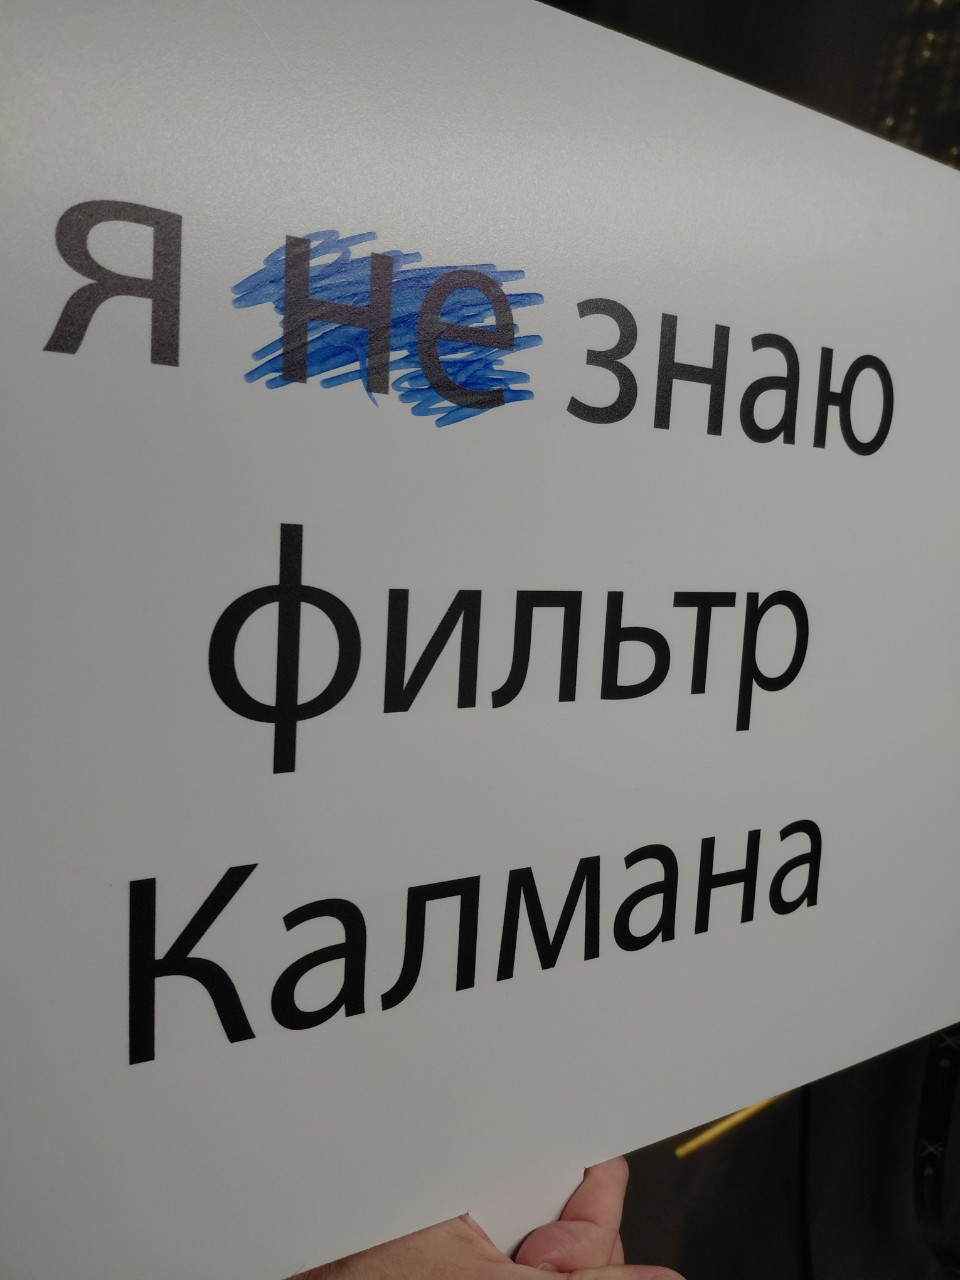